In [15]:
from langgraph.graph import StateGraph, START, END
from typing import Annotated, TypedDict
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv

In [16]:
load_dotenv()

True

In [17]:
class SubState(TypedDict):

    input_text: str
    translated_text: str

In [18]:
subgraph_llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

In [29]:
def translate_text(state: SubState):

    prompt = f"""
Translate the following text to Hindi. Keep it natural and clear. Do not add extra content.
Text:
{state["input_text"]}
""".strip()
    
    translated_text = subgraph_llm.invoke(prompt).content

    return {"translated_text": translated_text}

In [30]:
subgraph_builder = StateGraph(SubState)

subgraph_builder.add_node("translate_text", translate_text)

subgraph_builder.add_edge(START, "translate_text")
subgraph_builder.add_edge("translate_text", END)

subgraph = subgraph_builder.compile()

In [31]:
class ParentState(TypedDict):

    question: str
    answer_eng: str
    answer_hin: str

In [32]:
parent_llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

In [33]:
def generate_answer(state: ParentState):

    answer = parent_llm.invoke(f"You are a helpful assistant. Answer clearly.\n\nQuestion: {state["question"]}").content

    return {"answer_eng": answer}

In [34]:
def translate_answer(state: ParentState):

    # call the subgraph
    result = subgraph.invoke({ 'input_text': state['answer_eng']})

    return {'answer_hin': result['translated_text']}

In [35]:
parent_builder = StateGraph(ParentState)

parent_builder.add_node("answer", generate_answer)
parent_builder.add_node("translate", translate_answer)

parent_builder.add_edge(START, "answer")
parent_builder.add_edge("answer", "translate")
parent_builder.add_edge('translate', END)

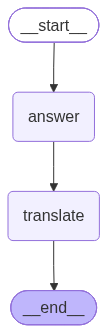

In [36]:
graph = parent_builder.compile()

graph

In [37]:
graph.invoke({"question": 'what is cloud computing'})

{'question': 'what is cloud computing',
 'answer_eng': [{'type': 'text',
   'text': '**Cloud computing** is the delivery of computing services over the internet—including data storage, servers, databases, networking, and software. \n\nInstead of keeping files on your own computer’s hard drive or running software from a local server, you access and store them securely on remote servers hosted on the internet (the "cloud").\n\nHere is a breakdown to help you understand it better:\n\n### 1. Everyday Examples\nIf you already use the internet for everyday tasks, you are likely using cloud computing:\n* **Google Drive, Dropbox, or iCloud:** You store photos and documents online, allowing you to access them from your phone, tablet, or computer anywhere in the world.\n* **Netflix or Spotify:** You stream movies and music without having to download massive files to your device.\n* **Gmail or Outlook:** Your emails are stored on remote servers, not on your personal device.\n\n### 2. The Main Ben